# Иерархическая кластеризация городов

Лабораторная работа по кластерному анализу. Датасет Economics of Cities: 48 городов мира, 1991 год.

## 1. Постановка задачи

Нужно выяснить, группируются ли города по трём экономическим показателям: годовой рабочей нагрузке (`Work`), уровню цен (`Price`) и уровню оплаты труда (`Salary`), и на сколько кластеров их разумно разделить. В этом ноутбуке задача решается агломеративной иерархической кластеризацией с тремя способами связи (Ward, Complete, Average) и евклидовым расстоянием.

Центральный вопрос работы - сравнение решений с двумя и тремя кластерами. Внутренние метрики качества обычно предпочитают более грубое разбиение, тогда как для содержательного анализа может быть полезнее более детальное. Задача состоит в том, чтобы честно показать этот компромисс, а не выбрать число кластеров по одной цифре.

Ноутбук самостоятельный: чтобы его выполнить, нужен только файл `Econom_Cities_data.csv` рядом с ним.

Подключаем библиотеки и задаём константы. Единые названия признаков и список метрик объявлены один раз, чтобы дальше не повторять их в коде.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import cdist, pdist
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

DATA_PATH = 'Econom_Cities_data.csv'
MISSING_CODE = -9999
FEATURES = ['Work', 'Price', 'Salary']
METRIC_COLUMNS = [
    'silhouette', 'davies_bouldin', 'calinski_harabasz', 'dunn'
]
RANDOM_STATE = 42

## 2. Описание данных

Файл `Econom_Cities_data.csv` содержит 48 городов мира и три числовых показателя за 1991 год:

| Признак | Смысл |
|---|---|
| `Work` | годовая рабочая нагрузка (порядок значений 1600-2400 соответствует числу рабочих часов в год) |
| `Price` | уровень цен на потребительскую корзину, индекс |
| `Salary` | уровень оплаты труда, индекс (максимум 100 у Цюриха) |

Единицы измерения в самом файле не описаны, поэтому `Price` и `Salary` трактуются как относительные индексы, а все выводы о «высоких» и «низких» значениях носят сравнительный характер.

Столбец `City` служит только для идентификации наблюдений и подписей на графиках. В расчёт расстояний он не входит.

В файле три технические особенности: столбцы разделены символом `;`, десятичным разделителем служит запятая, а пропуски закодированы числом `-9999`. Если оставить это число как есть, оно станет огромным выбросом и полностью исказит расстояния, поэтому на этапе загрузки его нужно заменить на настоящий пропуск.

## 3. Предобработка данных

Сначала загружаем файл с правильными разделителями и смотрим, сколько значений `-9999` содержит каждый признак.

In [2]:
raw = pd.read_csv(DATA_PATH, sep=';', decimal=',')
print(f'Строк: {raw.shape[0]}, столбцов: {raw.shape[1]}')
print(raw.dtypes, end='\n\n')

missing_mask = raw[FEATURES].eq(MISSING_CODE)
print('Количество значений -9999 по признакам:')
print(missing_mask.sum(), end='\n\n')
raw[missing_mask.any(axis=1)]

Строк: 48, столбцов: 4
City          str
Work        int64
Price     float64
Salary    float64
dtype: object

Количество значений -9999 по признакам:
Work      2
Price     0
Salary    2
dtype: int64



,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


Пропуски есть у двух городов, Каира и Джакарты, и у обоих отсутствуют сразу `Work` и `Salary`. Остаётся один признак из трёх (`Price`). Заполнять два недостающих показателя по одному оставшемуся было бы выдумыванием данных: любая оценка зарплаты и рабочей нагрузки по цене скрыла бы как раз ту информацию, ради которой строится кластеризация. Среднее или медиана по выборке притянули бы оба города к центру облака и исказили бы расстояния. Поэтому эти два города исключаются из основной модели, а не восстанавливаются. Потеря небольшая: 2 из 48 наблюдений.

In [3]:
data = raw.replace(MISSING_CODE, np.nan)
clean = data.dropna(subset=FEATURES).reset_index(drop=True)
excluded = sorted(set(data['City']) - set(clean['City']))
print(f'Исключено городов: {len(excluded)} ({", ".join(excluded)})')
print(f'В анализе: {len(clean)} городов')

Исключено городов: 2 (Cairo, Jakarta)
В анализе: 46 городов


Теперь проверяем, нет ли повторяющихся строк и названий, и смотрим базовые характеристики признаков в исходных единицах. Эти цифры понадобятся позже, чтобы сопоставлять профили кластеров с общим фоном.

In [4]:
print('Полных дубликатов строк:', raw.duplicated().sum())
print('Повторяющихся названий городов:', raw['City'].duplicated().sum())
print('Дубликатов по значениям признаков:',
      clean.duplicated(subset=FEATURES).sum())
clean[FEATURES].describe().round(2)

Полных дубликатов строк: 0
Повторяющихся названий городов: 0
Дубликатов по значениям признаков: 0


,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


Признаки измеряются в разных масштабах: `Work` меняется в тысячах, а `Price` и `Salary` в десятках. Без стандартизации евклидово расстояние определялось бы почти только `Work`. `StandardScaler` приводит каждый признак к нулевому среднему и единичному стандартному отклонению, и все три показателя вносят в расстояние сопоставимый вклад. Кластеризация далее выполняется на этих трёх стандартизированных признаках.

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(clean[FEATURES])
print('Средние:', X.mean(axis=0).round(3))
print('Стандартные отклонения:', X.std(axis=0).round(3))

Средние: [ 0. -0.  0.]
Стандартные отклонения: [1. 1. 1.]


## 4. Разведочный анализ

Смотрим распределения признаков, связи между ними и общую геометрию облака точек. От этого зависит, чего ожидать от кластеризации: есть ли выбросы, насколько признаки дублируют друг друга и можно ли показать данные на плоскости без заметной потери информации.

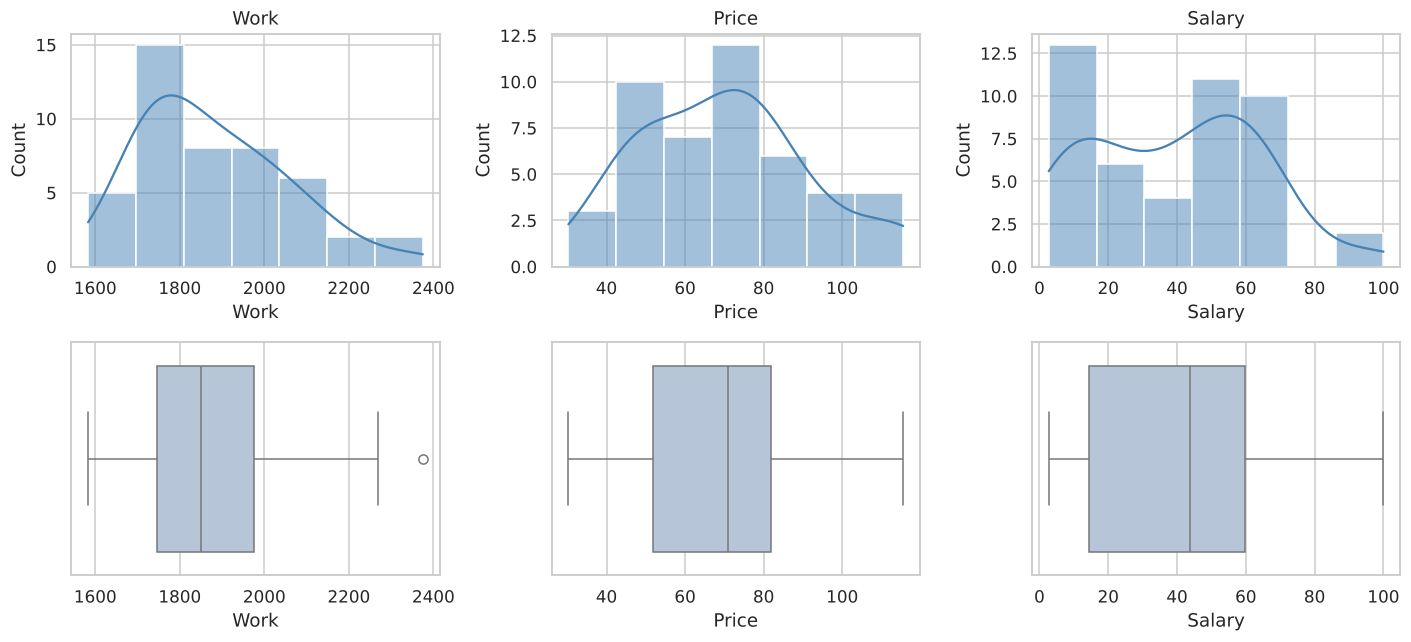

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for col, feature in enumerate(FEATURES):
    sns.histplot(clean[feature], kde=True, ax=axes[0, col],
                 color='steelblue')
    sns.boxplot(x=clean[feature], ax=axes[1, col], color='lightsteelblue')
    axes[0, col].set_title(feature)
plt.tight_layout()
plt.show()

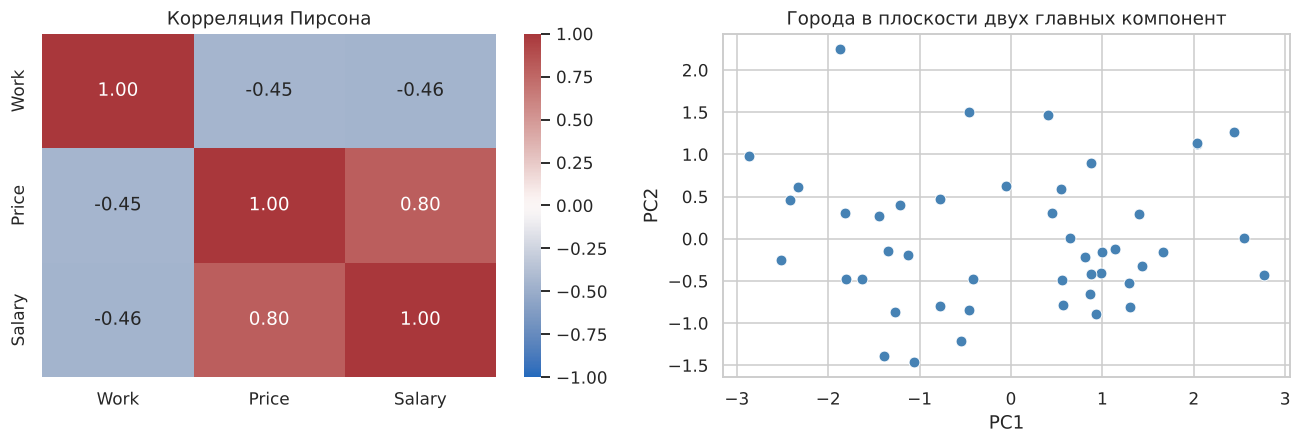

Доля дисперсии PC1 и PC2: [0.72  0.215]
Суммарно: 0.935


,PC1,PC2
Work,-0.48,0.87
Price,0.62,0.35
Salary,0.62,0.34


In [7]:
corr = clean[FEATURES].corr()
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca.fit_transform(X)
loadings = pd.DataFrame(pca.components_.T, index=FEATURES,
                        columns=['PC1', 'PC2']).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1,
            ax=axes[0])
axes[0].set_title('Корреляция Пирсона')
sns.scatterplot(x=pca_coords[:, 0], y=pca_coords[:, 1], ax=axes[1],
                color='steelblue', s=50)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Города в плоскости двух главных компонент')
plt.tight_layout()
plt.show()

print('Доля дисперсии PC1 и PC2:', pca.explained_variance_ratio_.round(3))
print('Суммарно:', pca.explained_variance_ratio_.sum().round(3))
loadings

Что видно из этих графиков и расчётов:

- Распределение `Work` скошено вправо (коэффициент асимметрии около 0,77): основная масса городов работает 1700-2000 часов в год, а несколько городов заметно выше. Для `Salary` и `Price` асимметрия слабее.
- `Price` и `Salary` сильно связаны (корреляция около 0,80). `Work` отрицательно связан с обоими показателями (около -0,45): чем выше нагрузка, тем в среднем ниже и цены, и зарплаты.
- Две первые главные компоненты объясняют примерно 93 % дисперсии, поэтому проекция на плоскость почти не теряет структуру. PC1 в основном противопоставляет «дорогие и высокооплачиваемые» города «дешёвым и малооплачиваемым» и в первую очередь опирается на `Price` и `Salary`, а PC2 в основном отражает `Work`.

Сильная связь `Price` и `Salary` означает, что эти два признака частично дублируют друг друга и «вес» этой оси в расстоянии выше, чем у `Work`. Это стоит помнить при интерпретации. PCA используется только для рисунков: все модели обучаются на трёх исходных стандартизированных признаках.

## 5. Теоретическое описание метода

Агломеративная кластеризация начинается с того, что каждый город образует отдельный кластер. На каждом шаге объединяются два ближайших кластера, и так до тех пор, пока не останется один. Результат - дерево слияний (дендрограмма), которое можно разрезать на любом уровне и получить любое число кластеров. Высота слияния показывает, насколько далеко друг от друга были объединяемые группы, поэтому резкий скачок высоты говорит о том, что дальше объединяются уже заметно различающиеся кластеры.

Способы связи определяют, как измеряется расстояние между кластерами:

- **Ward**: объединяются те кластеры, для которых прирост внутрикластерной суммы квадратов минимален. Метод работает только с евклидовым расстоянием и склонен давать компактные группы сопоставимого размера.
- **Complete**: расстояние между кластерами равно наибольшему из расстояний между их объектами. Группы получаются компактными, но один далёкий город может надолго задержать объединение.
- **Average**: расстояние равно среднему по всем парам объектов. Метод занимает промежуточное положение, но легче отделяет одиночные выбросы в совсем маленькие кластеры.

Качество самого дерева можно оценить кофенетической корреляцией: она показывает, насколько высоты слияний воспроизводят исходные попарные расстояния между городами. Чем она выше, тем меньше дерево искажает данные.


### Метрики качества

Для оценки разбиений применяются четыре внутренних индекса. Они опираются на разные свойства кластеров, и их значения нельзя сводить в один общий рейтинг.

| Метрика | Что измеряет | Как читать |
|---|---|---|
| Silhouette | для каждого объекта сравнивает среднее расстояние до своего кластера и до ближайшего чужого; затем усредняется | от -1 до 1, чем выше, тем лучше |
| Davies-Bouldin | среднюю «похожесть» каждого кластера на самого близкого соседа: отношение суммарного разброса к расстоянию между центрами | чем ниже, тем лучше |
| Calinski-Harabasz | отношение межкластерной дисперсии к внутрикластерной с поправкой на число кластеров | чем выше, тем лучше |
| Dunn | наименьшее расстояние между двумя кластерами, делённое на наибольший диаметр кластера | чем выше, тем лучше |

Особенности, важные для интерпретации. Calinski-Harabasz и Davies-Bouldin неявно ориентированы на компактные округлые кластеры. Dunn зависит только от двух экстремальных расстояний, поэтому один необычный город заметно меняет его значение. Silhouette полезен ещё и тем, что даёт оценку для каждого города, а не только общую. Все четыре индекса не учитывают содержательный смысл групп, поэтому дополнительно рассматриваются размеры кластеров и профили в исходных единицах.

## 6. Обоснование выбора параметров

**Расстояние.** Используется евклидово расстояние на стандартизированных признаках. Для Ward оно обязательно, а для Complete и Average выбирается для сопоставимости методов.

**Способы связи.** Рассматриваются все три метода, как требует постановка. Они реагируют на структуру данных по-разному, и расхождение между ними само по себе служит проверкой устойчивости.

**Число кластеров.** Рассматривается диапазон от 2 до 8. Одного кластера не бывает по определению метрик, а при 46 городах разбиение на 8 групп уже даёт в среднем по 5-6 городов в группе, и дальнейшее дробление теряет смысл.

Сначала подключаем вспомогательные функции.

Собираем функции, которые будут вызываться много раз. Индекс Данна в `scikit-learn` отсутствует, поэтому он реализован самостоятельно через матрицы попарных расстояний: `pdist` даёт диаметры кластеров, `cdist` даёт расстояния между объектами разных кластеров.

In [8]:
def dunn_index(points, labels):
    groups = [points[labels == c] for c in np.unique(labels)]
    max_diameter = max(
        pdist(group).max() if len(group) > 1 else 0.0 for group in groups
    )
    min_separation = min(
        cdist(first, second).min()
        for i, first in enumerate(groups)
        for second in groups[i + 1:]
    )
    return min_separation / max_diameter


def evaluate_partition(points, labels):
    return {
        'silhouette': silhouette_score(points, labels),
        'davies_bouldin': davies_bouldin_score(points, labels),
        'calinski_harabasz': calinski_harabasz_score(points, labels),
        'dunn': dunn_index(points, labels),
    }


def format_sizes(labels):
    counts = pd.Series(labels).value_counts().sort_values(ascending=False)
    return ' / '.join(str(n) for n in counts.values)

In [9]:
def relabel_by_salary(labels, salary):
    order = pd.Series(salary).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order, start=1)}
    return np.array([mapping[label] for label in labels])


def cluster_profile(frame, labels):
    grouped = frame.assign(cluster=labels).groupby('cluster')[FEATURES]
    profile = pd.concat([
        grouped.size().rename('n'),
        grouped.mean().round(1).add_suffix('_mean'),
        grouped.median().round(1).add_suffix('_median'),
    ], axis=1)
    return profile


def print_cities(frame, labels):
    names = frame['City'].str.replace('_', ' ')
    for cluster, group in names.groupby(labels):
        title = 'Шум' if cluster == -1 else f'Кластер {cluster}'
        print(f'  {title} ({len(group)}): {", ".join(group)}')


def weak_cities(frame, points, labels, threshold=0.25):
    table = pd.DataFrame({
        'city': frame['City'].str.replace('_', ' '),
        'cluster': labels,
        'silhouette': silhouette_samples(points, labels).round(3),
    })
    return table[table['silhouette'] < threshold].sort_values('silhouette')


def silhouette_summary(points, labels):
    values = silhouette_samples(points, labels)
    return pd.DataFrame({'cluster': labels, 'value': values}).groupby(
        'cluster')['value'].agg(
        n='size', mean='mean', min='min',
        below_zero=lambda s: int((s < 0).sum()),
        below_025=lambda s: int((s < 0.25).sum()),
    ).round(3)

In [10]:
def plot_clusters(ax, labels, title, annotate=True):
    palette = sns.color_palette('Set2', 8)
    for cluster in np.unique(labels):
        mask = labels == cluster
        if cluster == -1:
            ax.scatter(pca_coords[mask, 0], pca_coords[mask, 1], s=55,
                       color='gray', marker='x', label='Шум')
        else:
            ax.scatter(pca_coords[mask, 0], pca_coords[mask, 1], s=60,
                       color=palette[cluster - 1], edgecolor='white',
                       label=f'Кластер {cluster}')
    if annotate:
        names = clean['City'].str.replace('_', ' ')
        for (x_pos, y_pos), name in zip(pca_coords, names):
            ax.annotate(name, (x_pos, y_pos), fontsize=7.5,
                        xytext=(3, 3), textcoords='offset points')
    ratio = pca.explained_variance_ratio_
    ax.set_xlabel(f'PC1 ({ratio[0]:.0%})')
    ax.set_ylabel(f'PC2 ({ratio[1]:.0%})')
    ax.set_title(title)
    ax.legend(loc='best', fontsize=8)


def plot_feature_boxes(labels, suptitle):
    frame = clean.assign(cluster=labels)
    base = sns.color_palette('Set2', 8)
    palette = {
        cluster: 'gray' if cluster == -1 else base[cluster - 1]
        for cluster in np.unique(labels)
    }
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, feature in zip(axes, FEATURES):
        sns.boxplot(data=frame, x='cluster', y=feature, hue='cluster',
                    palette=palette, legend=False, ax=ax)
        sns.stripplot(data=frame, x='cluster', y=feature, color='black',
                      size=3, alpha=0.6, ax=ax)
        ax.set_title(feature)
    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

Строим деревья слияний для всех трёх методов и считаем кофенетическую корреляцию. Дендрограммы нужны, чтобы увидеть, на каких высотах происходят крупные слияния, то есть где естественные границы между группами.

In [11]:
METHODS = ['ward', 'complete', 'average']
K_RANGE = range(2, 9)

linkages = {
    method: linkage(X, method=method, metric='euclidean')
    for method in METHODS
}
distances = pdist(X)
cophenetic = pd.Series({
    method: cophenet(tree, distances)[0] for method, tree in linkages.items()
}, name='cophenetic_correlation').round(3)
cophenetic

ward        0.703
complete    0.719
average     0.741
Name: cophenetic_correlation, dtype: float64

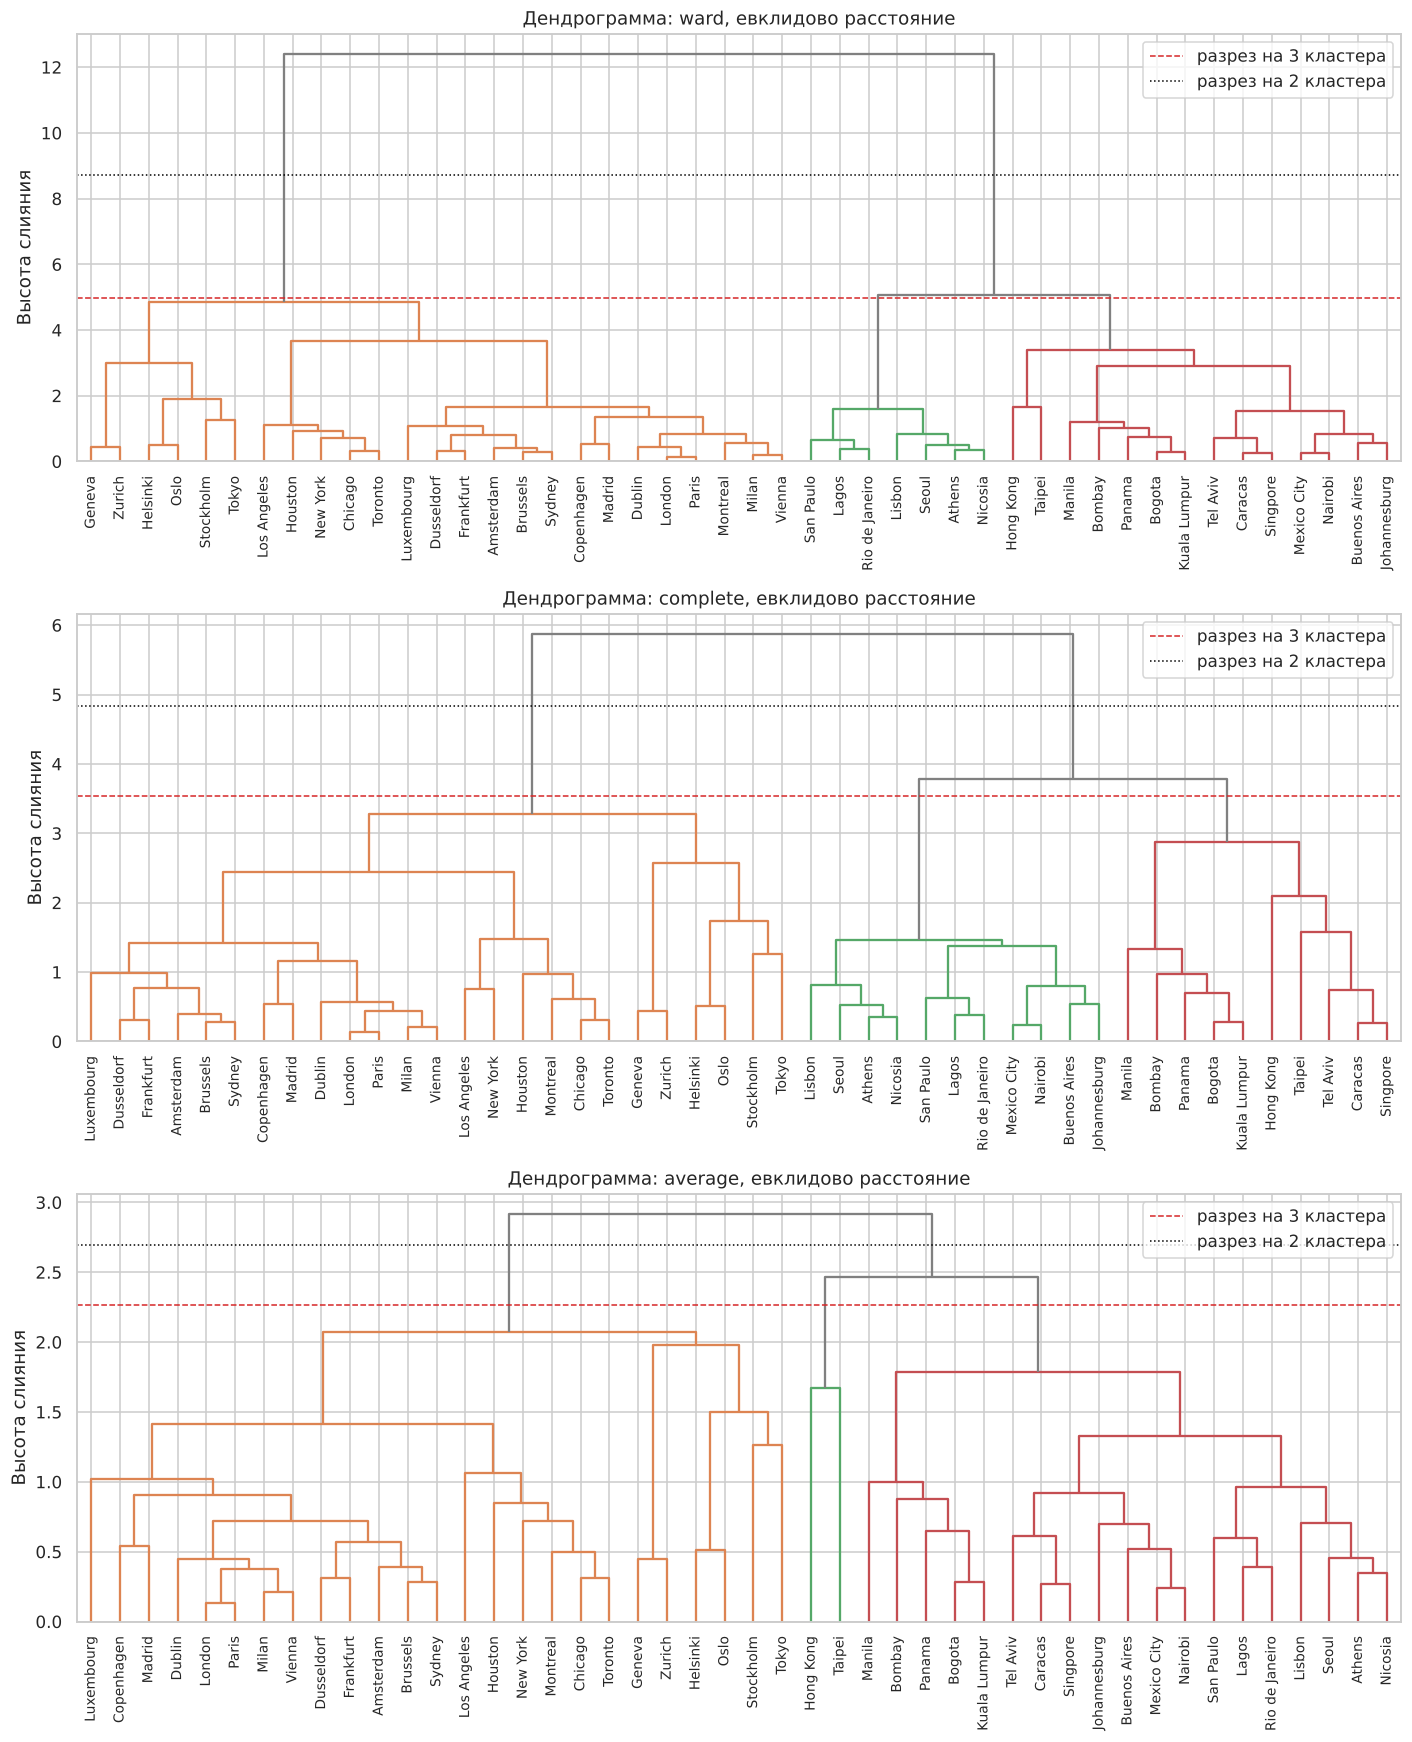

In [12]:
city_names = clean['City'].str.replace('_', ' ').values
fig, axes = plt.subplots(3, 1, figsize=(13, 16))
for ax, (method, tree) in zip(axes, linkages.items()):
    cut_3 = (tree[-3, 2] + tree[-2, 2]) / 2
    cut_2 = (tree[-2, 2] + tree[-1, 2]) / 2
    dendrogram(tree, labels=city_names, color_threshold=cut_3,
               above_threshold_color='gray', leaf_rotation=90,
               leaf_font_size=9, ax=ax)
    ax.axhline(cut_3, ls='--', color='tab:red', lw=1,
               label='разрез на 3 кластера')
    ax.axhline(cut_2, ls=':', color='black', lw=1,
               label='разрез на 2 кластера')
    ax.set_title(f'Дендрограмма: {method}, евклидово расстояние')
    ax.set_ylabel('Высота слияния')
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

По дендрограммам видно следующее.

- У Ward последнее слияние происходит на высоте около 12,4, предыдущее около 5,1, а следующее за ним около 4,9. Между одним и двумя кластерами лежит огромный разрыв, а между разрезами на 3 и на 4 кластера его почти нет. Деление на две группы выражено намного сильнее любого более детального.
- Complete и Average показывают ту же картину в более мягком виде: последние слияния около 5,9, 3,8 и 3,3 у Complete и около 2,9, 2,5 и 2,1 у Average. Двухгрупповая структура заметна, дальнейшие уровни расположены плотнее.
- Левая крупная ветвь во всех трёх деревьях одна и та же: дорогие и высокооплачиваемые города (Цюрих, Женева, Стокгольм, Токио, Нью-Йорк и другие). Правая ветвь неоднородна, и именно она делится при переходе к трём кластерам: Ward разбивает её на группы из 14 и 7 городов, а Average отделяет Гонконг и Тайбэй в группу из двух городов.
- Кофенетическая корреляция близка у всех методов (0,70 у Ward, 0,72 у Complete, 0,74 у Average). Ни одно из деревьев не искажает расстояния заметно сильнее остальных, поэтому выбрать способ связи только по качеству дерева нельзя. Сравнивать их придётся по метрикам и по содержательной интерпретации.

## 7. Построение модели

Для каждого способа связи дерево разрезается на 2, 3, ..., 8 кластеров, и каждое разбиение оценивается всеми четырьмя метриками. Номера кластеров упорядочены по возрастанию средней зарплаты (кластер 1 - самая низкая), чтобы номера имели одинаковый смысл при разных `k` и методах.

In [13]:
partitions = {}
rows = []
for method, tree in linkages.items():
    for k in K_RANGE:
        raw_labels = fcluster(tree, k, criterion='maxclust')
        labels = relabel_by_salary(raw_labels, clean['Salary'])
        assert len(np.unique(labels)) == k
        partitions[(method, k)] = labels
        rows.append({
            'method': method,
            'k': k,
            **evaluate_partition(X, labels),
            'min_size': int(np.bincount(labels)[1:].min()),
            'sizes': format_sizes(labels),
        })
results = pd.DataFrame(rows)
display(results.round(3))

,method,k,silhouette,davies_bouldin,calinski_harabasz,dunn,min_size,sizes
0,ward,2,0.470,0.808,55.351,0.223,21,25 / 21
1,ward,3,0.361,0.818,39.917,0.170,7,25 / 14 / 7
2,ward,4,0.355,1.002,38.930,0.194,6,19 / 14 / 7 / 6
3,ward,5,0.348,0.905,37.209,0.133,5,14 / 14 / 7 / 6 / 5
4,ward,6,0.366,0.889,37.964,0.148,2,14 / 12 / 7 / 6 / 5 / 2
5,ward,7,0.396,0.778,39.411,0.176,2,14 / 12 / 7 / 5 / 4 / 2 / 2
6,ward,8,0.399,0.774,43.532,0.220,2,14 / 7 / 7 / 5 / 5 / 4 / 2 / 2
7,complete,2,0.470,0.808,55.351,0.223,21,25 / 21
8,complete,3,0.388,0.905,41.146,0.144,10,25 / 11 / 10
9,complete,4,0.366,1.063,40.342,0.165,6,19 / 11 / 10 / 6


## 8. Оценка качества кластеризации

Таблица выше содержит все варианты. Для удобства сравнения методов раскладываем каждую метрику по числу кластеров.

In [14]:
for column in METRIC_COLUMNS:
    print(column)
    display(results.pivot(index='k', columns='method',
                          values=column).round(3))

silhouette


method,average,complete,ward
k,,,
2,0.470,0.470,0.470
3,0.420,0.388,0.361
4,0.372,0.366,0.355
5,0.381,0.379,0.348
6,0.383,0.390,0.366
7,0.350,0.395,0.396
8,0.354,0.393,0.399


davies_bouldin


method,average,complete,ward
k,,,
2,0.808,0.808,0.808
3,0.791,0.905,0.818
4,0.966,1.063,1.002
5,0.787,0.996,0.905
6,0.755,0.842,0.889
7,0.638,0.813,0.778
8,0.611,0.699,0.774


calinski_harabasz


method,average,complete,ward
k,,,
2,55.351,55.351,55.351
3,35.028,41.146,39.917
4,33.494,40.342,38.930
5,28.827,36.453,37.209
6,33.557,34.781,37.964
7,29.138,40.155,39.411
8,26.652,40.048,43.532


dunn


method,average,complete,ward
k,,,
2,0.223,0.223,0.223
3,0.258,0.144,0.170
4,0.264,0.165,0.194
5,0.264,0.184,0.133
6,0.249,0.193,0.148
7,0.249,0.202,0.176
8,0.249,0.244,0.220


Те же значения на графиках. Направление «лучше» у метрик разное, оно указано в заголовках.

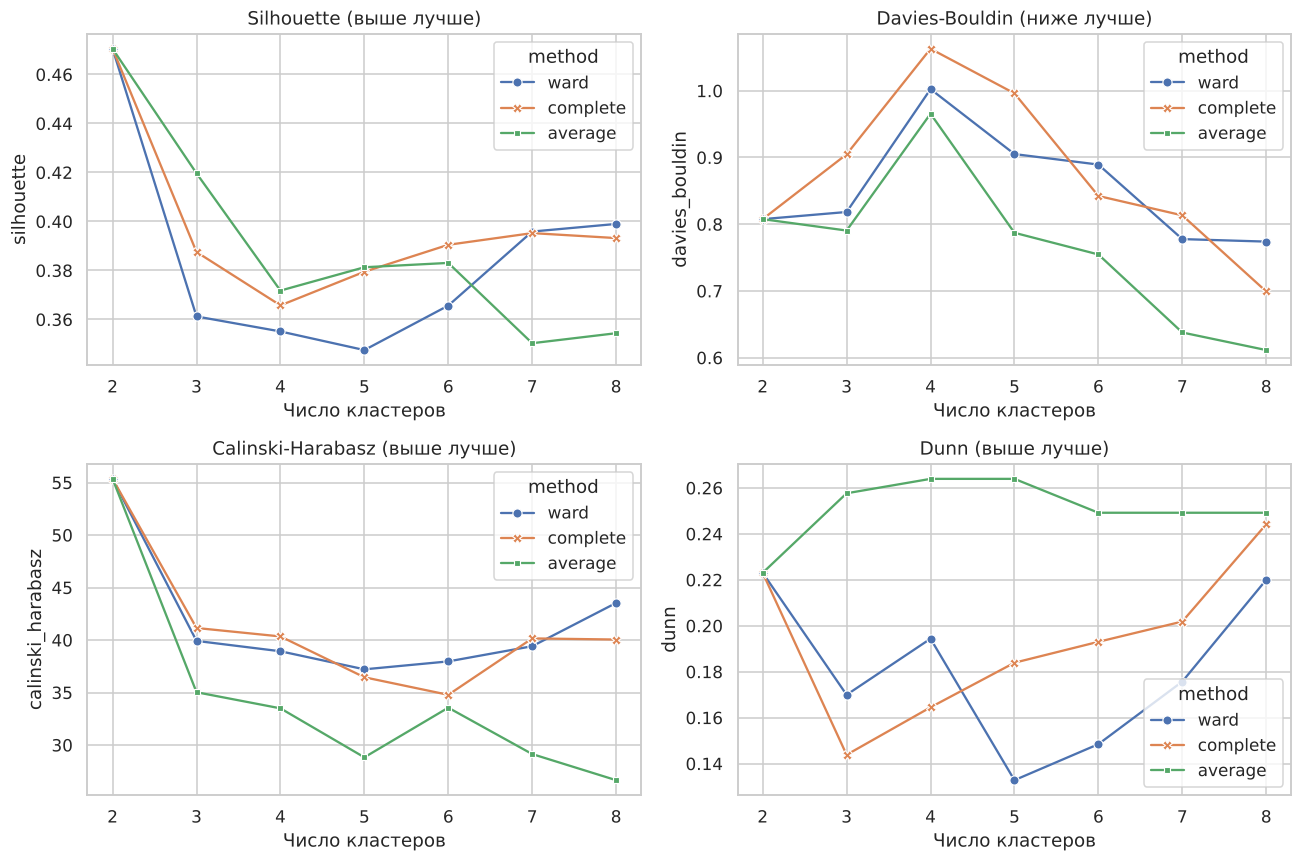

In [15]:
metric_titles = {
    'silhouette': 'Silhouette (выше лучше)',
    'davies_bouldin': 'Davies-Bouldin (ниже лучше)',
    'calinski_harabasz': 'Calinski-Harabasz (выше лучше)',
    'dunn': 'Dunn (выше лучше)',
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (column, title) in zip(axes.ravel(), metric_titles.items()):
    sns.lineplot(data=results, x='k', y=column, hue='method',
                 style='method', markers=True, dashes=False, ax=ax)
    ax.set_title(title)
    ax.set_xticks(list(K_RANGE))
    ax.set_xlabel('Число кластеров')
plt.tight_layout()
plt.show()

Размеры кластеров показывают, не получаются ли «разбиения» из одного большого кластера и нескольких единичных городов. Ниже размеры кластеров для каждого метода и числа кластеров, от большего к меньшему.

In [16]:
display(results.pivot(index='k', columns='method', values='sizes'))

method,average,complete,ward
k,,,
2,25 / 21,25 / 21,25 / 21
3,25 / 19 / 2,25 / 11 / 10,25 / 14 / 7
4,19 / 19 / 6 / 2,19 / 11 / 10 / 6,19 / 14 / 7 / 6
5,19 / 19 / 4 / 2 / 2,19 / 11 / 6 / 5 / 5,14 / 14 / 7 / 6 / 5
6,19 / 14 / 5 / 4 / 2 / 2,19 / 11 / 5 / 5 / 4 / 2,14 / 12 / 7 / 6 / 5 / 2
7,19 / 14 / 5 / 4 / 2 / 1 / 1,13 / 11 / 6 / 5 / 5 / 4 / 2,14 / 12 / 7 / 5 / 4 / 2 / 2
8,19 / 14 / 5 / 2 / 2 / 2 / 1 / 1,13 / 11 / 6 / 5 / 4 / 4 / 2 / 1,14 / 7 / 7 / 5 / 5 / 4 / 2 / 2


Что показывают таблицы и графики.

- При `k=2` все три метода дают одно и то же разбиение (25 и 21 город), поэтому и метрики совпадают: Silhouette 0,470, Davies-Bouldin 0,808, Calinski-Harabasz 55,35, Dunn 0,223.
- Silhouette и Calinski-Harabasz достигают максимума при `k=2` для всех методов. При `k>2` Calinski-Harabasz ни у одного метода не превышает 44, а Silhouette не выше 0,42.
- Davies-Bouldin и Dunn ведут себя иначе. У Average Davies-Bouldin опускается до 0,791 при `k=3` и до 0,611 при `k=8`, а Dunn при `k` от 3 до 8 держится около 0,25-0,26, выше значения при `k=2`. Размеры кластеров объясняют это: уже при `k=3` Average выделяет группу из двух городов, а при `k=7` и `k=8` появляются кластеры из одного города. Davies-Bouldin и Dunn по построению поощряют изоляцию отдельных объектов, поэтому их улучшение здесь не означает более удачной сегментации.
- У Ward и Complete при `k=6` тоже появляются кластеры из двух городов, а у Complete при `k=8` даже из одного. Диапазон 6-8 поэтому не считается содержательно полезным, хотя некоторые метрики там снова немного растут (например, Silhouette у Ward 0,399 при `k=8`).
- Решения с `k=3` заметно различаются по составу: 25 / 14 / 7 у Ward, 25 / 11 / 10 у Complete и 25 / 19 / 2 у Average. Третий кластер зависит от способа связи сильнее, чем второй.

### Подробное сравнение двух и трёх кластеров

Сначала проверяем, воспроизводятся ли ориентировочные значения предварительного расчёта для Ward, затем смотрим на все три метода при `k=2` и `k=3`.

In [17]:
reference = pd.DataFrame(
    [[0.470, 0.808, 55.351, 0.223], [0.361, 0.818, 39.917, 0.170]],
    index=pd.Index([2, 3], name='k'), columns=METRIC_COLUMNS,
)
ward_check = results[(results['method'] == 'ward')
                     & results['k'].isin([2, 3])]
recomputed = ward_check.set_index('k')[METRIC_COLUMNS].round(3)
print('Максимальное расхождение с предварительным расчётом:',
      (recomputed - reference).abs().max().max())

Максимальное расхождение с предварительным расчётом: 0.0


In [18]:
focus = results[results['k'].isin([2, 3])].sort_values(['method', 'k'])
display(focus.drop(columns='min_size').round(3))

for first, second in [('ward', 'complete'), ('ward', 'average')]:
    ari = adjusted_rand_score(partitions[(first, 2)],
                              partitions[(second, 2)])
    print(f'ARI двухкластерных решений {first} и {second}: {ari:.3f}')

,method,k,silhouette,davies_bouldin,calinski_harabasz,dunn,sizes
14,average,2,0.470,0.808,55.351,0.223,25 / 21
15,average,3,0.420,0.791,35.028,0.258,25 / 19 / 2
7,complete,2,0.470,0.808,55.351,0.223,25 / 21
8,complete,3,0.388,0.905,41.146,0.144,25 / 11 / 10
0,ward,2,0.470,0.808,55.351,0.223,25 / 21
1,ward,3,0.361,0.818,39.917,0.170,25 / 14 / 7


ARI двухкластерных решений ward и complete: 1.000
ARI двухкластерных решений ward и average: 1.000


Как трёхкластерное решение Ward соотносится с двухкластерным: делит ли оно один из двух кластеров или перемешивает город между ними.

In [19]:
display(pd.crosstab(partitions[('ward', 2)], partitions[('ward', 3)],
                    rownames=['k=2'], colnames=['k=3']))

for method in ['complete', 'average']:
    print(f'{method}, k=3:')
    print_cities(clean, partitions[(method, 3)])

k=3,1,2,3
k=2,,,
1,14,7,0
2,0,0,25


complete, k=3:
  Кластер 1 (10): Bogota, Bombay, Caracas, Hong Kong, Kuala Lumpur, Manila, Panama, Singpore, Taipei, Tel Aviv
  Кластер 2 (11): Athens, Buenos Aires, Johannesburg, Lagos, Lisbon, Mexico City, Nairobi, Nicosia, Rio de Janeiro, San Paulo, Seoul
  Кластер 3 (25): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
average, k=3:
  Кластер 1 (19): Athens, Bogota, Bombay, Buenos Aires, Caracas, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Tel Aviv
  Кластер 2 (2): Hong Kong, Taipei
  Кластер 3 (25): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, V

Общий Silhouette скрывает, как распределена уверенность по городам. Смотрим оценки отдельных городов в решениях Ward: сколько городов имеют отрицательный Silhouette (по оценке ближе к чужому кластеру) и сколько расположены слабо (меньше 0,25).

In [20]:
for k in (2, 3):
    labels = partitions[('ward', k)]
    print(f'Ward, k={k}')
    display(silhouette_summary(X, labels))
    print('Города с Silhouette ниже 0,25:')
    display(weak_cities(clean, X, labels))

Ward, k=2


,n,mean,min,below_zero,below_025
cluster,,,,,
1,21,0.450,0.095,0,3
2,25,0.488,0.098,0,1


Города с Silhouette ниже 0,25:


,city,cluster,silhouette
40,Taipei,1,0.095
15,Houston,2,0.098
36,Seoul,1,0.197
1,Athens,1,0.227


Ward, k=3


,n,mean,min,below_zero,below_025
cluster,,,,,
1,14,0.216,-0.220,3,7
2,7,0.578,0.491,0,0
3,25,0.382,0.081,0,4


Города с Silhouette ниже 0,25:


,city,cluster,silhouette
16,Johannesburg,1,-0.220
25,Mexico City,1,-0.101
28,Nairobi,1,-0.031
5,Buenos Aires,1,0.059
0,Amsterdam,3,0.081
15,Houston,3,0.087
41,Tel Aviv,1,0.152
40,Taipei,1,0.186
9,Dublin,3,0.192
3,Bombay,1,0.224


**Итог сравнения двух и трёх кластеров.**

Для Ward переход от `k=2` к `k=3` ухудшает или оставляет без изменений все метрики: Silhouette падает с 0,470 до 0,361 (минус 23 %), Calinski-Harabasz с 55,4 до 39,9 (минус 28 %), Dunn с 0,223 до 0,170 (минус 24 %), а Davies-Bouldin почти не меняется (0,808 и 0,818, чуть хуже). У Complete ухудшение сопоставимое. Единственное исключение - Average: при `k=3` у него лучше Davies-Bouldin (0,791) и Dunn (0,258), но достигается это выделением Гонконга и Тайбэя в группу из двух городов, и сегментацией назвать это нельзя.

**Как устроено трёхкластерное решение.** Таблица пересечений показывает, что Ward при `k=3` целиком сохраняет группу из 25 дорогих городов и делит только группу из 21 города на 14 и 7. Новый кластер возникает внутри «низкой» ветви и не затрагивает остальных.

**Цена этого деления** видна по оценкам Silhouette для отдельных городов. В двухкластерном решении отрицательных значений нет, а ниже 0,25 лежат четыре города. В трёхкластерном решении отрицательный Silhouette у трёх городов (Йоханнесбург, Мехико, Найроби), а ниже 0,25 лежат одиннадцать. Семь из них, включая все три с отрицательным значением, относятся к кластеру из 14 городов: его средний Silhouette 0,216 против 0,578 у компактного кластера из семи городов. Остальные четыре (Амстердам, Хьюстон, Дублин, Лос-Анджелес) принадлежат кластеру дорогих городов, как и в двухкластерном решении. Граничат с этим кластером и четыре города (Буэнос-Айрес, Йоханнесбург, Мехико, Найроби). Complete проводит границу иначе: его «средняя» группа из 11 городов - это те же семь городов Ward плюс как раз эти четыре. Значит, граница внутри «низкой» ветви проходит по непрерывному переходу, а не по естественному разрыву, и её положение зависит от метода.

## 9. Интерпретация результатов

Для интерпретации берём Ward: он минимизирует рост внутрикластерной дисперсии, то есть согласован с евклидовой геометрией, на которой считаются метрики. Профили считаются в исходных единицах, а не в стандартизированных, чтобы их можно было читать как реальные показатели городов.

In [21]:
for k in (2, 3):
    labels = partitions[('ward', k)]
    print(f'Ward, k={k}: средние и медианные значения признаков')
    display(cluster_profile(clean, labels))
    print('Минимум и максимум признаков по кластерам:')
    display(clean.assign(cluster=labels).groupby('cluster')[FEATURES]
            .agg(['min', 'max']).round(1))
    print_cities(clean, labels)
    print()

Ward, k=2: средние и медианные значения признаков


,n,Work_mean,Price_mean,Salary_mean,Work_median,Price_median,Salary_median
cluster,,,,,,,
1,21,1987.9,52.4,16.3,1971.0,49.8,12.5
2,25,1789.2,85.0,59.0,1768.0,79.8,58.2


Минимум и максимум признаков по кластерам:


Work         Price        Salary       
            min     max   min    max    min    max
cluster                                           
1        1742.0  2375.0  30.3   84.3    2.7   34.5
2        1583.0  2068.0  65.6  115.5   39.2  100.0

  Кластер 1 (21): Athens, Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Taipei, Tel Aviv
  Кластер 2 (25): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich

Ward, k=3: средние и медианные значения признаков


,n,Work_mean,Price_mean,Salary_mean,Work_median,Price_median,Salary_median
cluster,,,,,,,
1,14,2082.4,53.1,14.9,2047.0,50.4,12.0
2,7,1798.9,50.9,19.2,1792.0,48.9,18.8
3,25,1789.2,85.0,59.0,1768.0,79.8,58.2


Минимум и максимум признаков по кластерам:


Work         Price        Salary       
            min     max   min    max    min    max
cluster                                           
1        1944.0  2375.0  30.3   84.3    4.0   34.5
2        1742.0  1856.0  45.2   58.3    2.7   32.7
3        1583.0  2068.0  65.6  115.5   39.2  100.0

  Кластер 1 (14): Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Manila, Mexico City, Nairobi, Panama, Singpore, Taipei, Tel Aviv
  Кластер 2 (7): Athens, Lagos, Lisbon, Nicosia, Rio de Janeiro, San Paulo, Seoul
  Кластер 3 (25): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich



Боксплоты показывают не только центры, но и разброс внутри кластеров. Это позволяет судить, различаются ли группы по каждому признаку отдельно или только по их сочетанию.

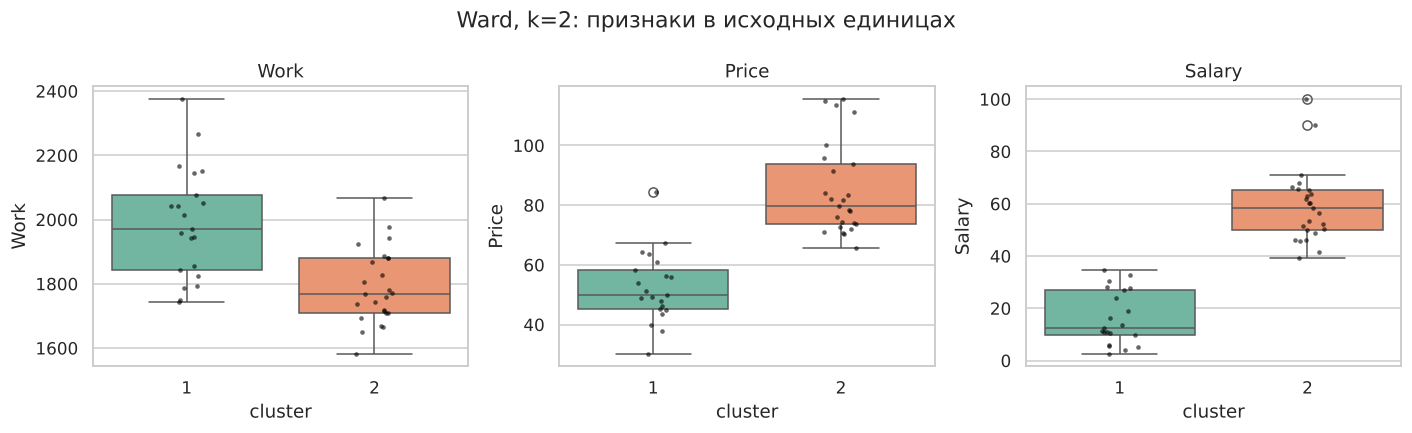

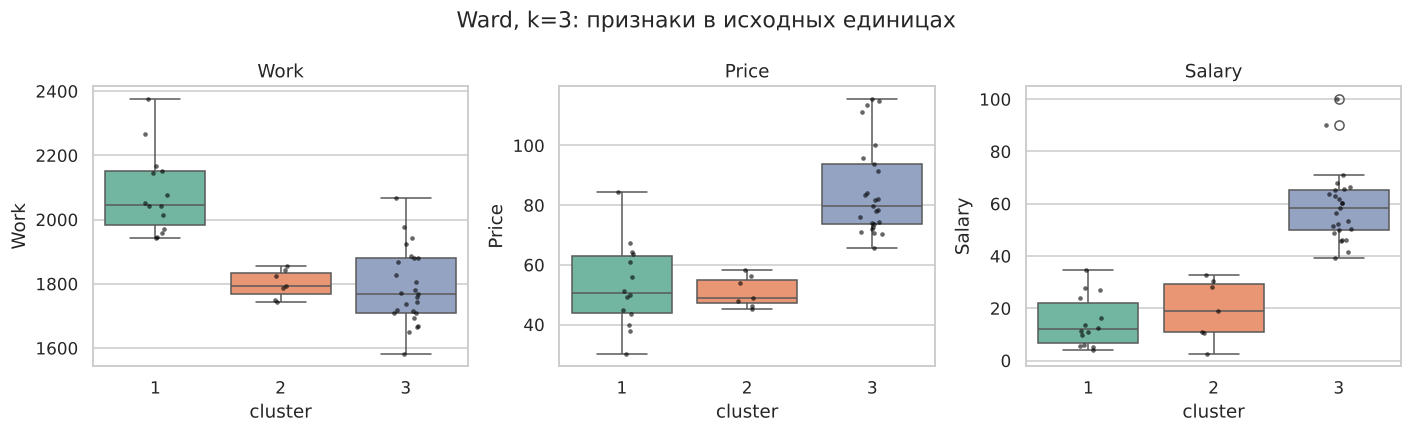

In [22]:
for k in (2, 3):
    plot_feature_boxes(partitions[('ward', k)],
                       f'Ward, k={k}: признаки в исходных единицах')

Карта городов в плоскости двух главных компонент. Кластеризация построена на трёх признаках, PCA используется только для рисунка.

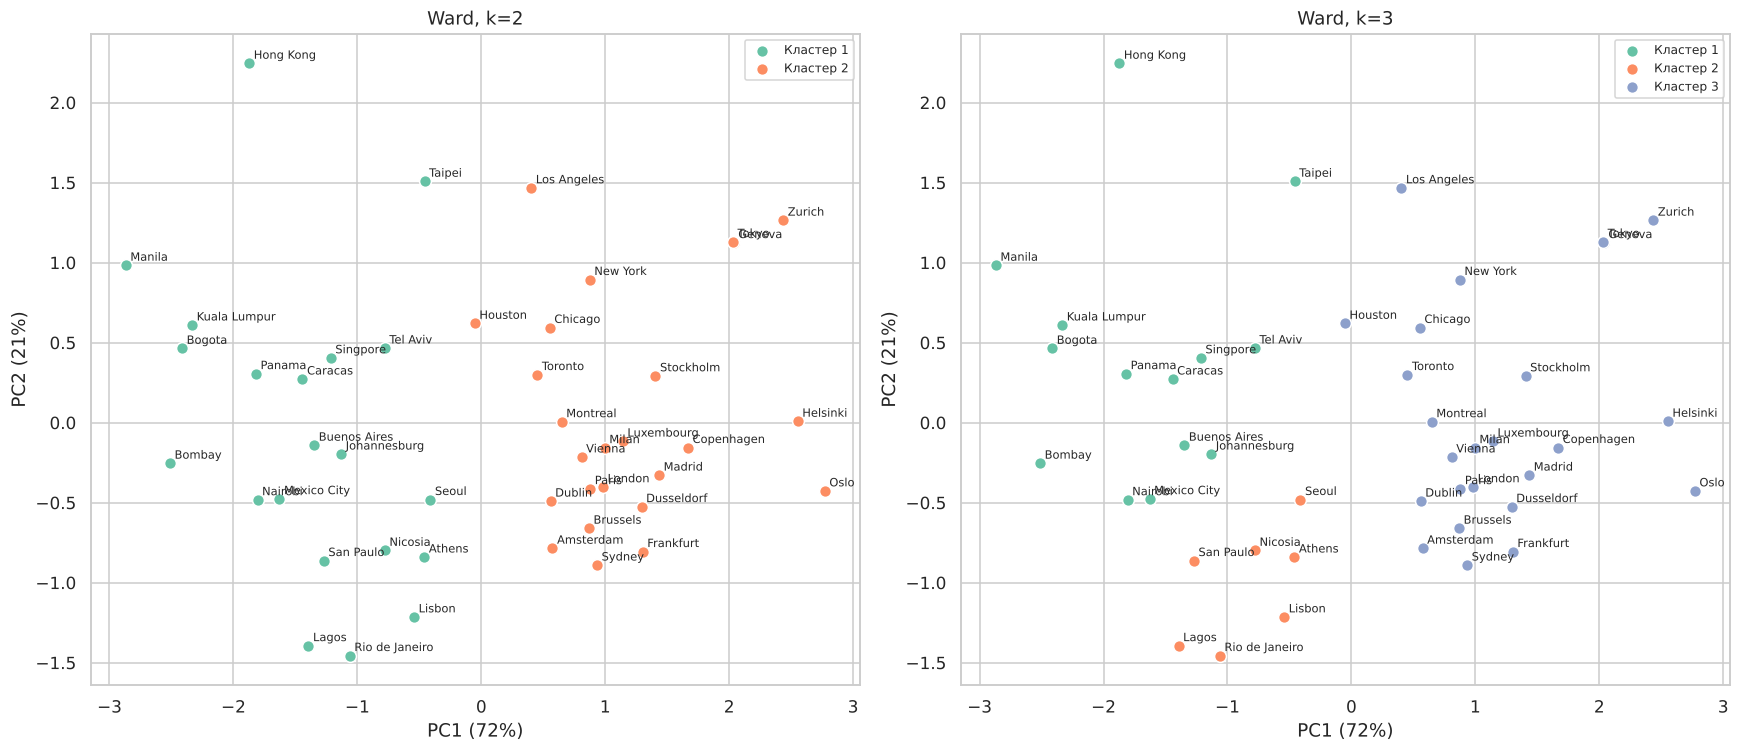

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, k in zip(axes, (2, 3)):
    plot_clusters(ax, partitions[('ward', k)], f'Ward, k={k}')
plt.tight_layout()
plt.show()

**Два кластера.** Кластер 2 (25 городов) - дорогие и высокооплачиваемые города: в среднем `Work` 1789 часов, `Price` 85,0, `Salary` 59,0. Кластер 1 (21 город) - дешёвые и малооплачиваемые: `Work` 1988, `Price` 52,4, `Salary` 16,3. Зарплата в первой группе выше примерно в 3,6 раза (59,0 против 16,3), цены выше в 1,6 раза, а рабочая нагрузка ниже примерно на 200 часов, то есть на 10 %. Разрыв по зарплате заметно больше, чем по ценам. Медианы (58,2 против 12,5 по `Salary`) подтверждают, что различие создают не отдельные города. Внутри кластера 1 есть и Гонконг, Тайбэй, Сингапур, Тель-Авив, Сеул, и Лагос, Бомбей, Найроби: по этим трём показателям в 1991 году они образуют одну группу. Кластер 2 включает Лос-Анджелес с его длинной рабочей нагрузкой (2068 часов) и Цюрих с Женевой на верхней границе по цене и зарплате.

**Три кластера.** Кластер 3 (25 городов) остаётся тем же. «Низкая» группа распадается на кластер 1 (14 городов: `Work` 2082, `Price` 53,1, `Salary` 14,9) и кластер 2 (7 городов: `Work` 1799, `Price` 50,9, `Salary` 19,2). Цены у них практически равны, зарплаты различаются на несколько пунктов (медианы 12,0 и 18,8), а рабочая нагрузка отличается примерно на 280 часов (около 14 %). Диапазоны `Work` в этих кластерах не пересекаются: 1944-2375 и 1742-1856 часов. Следовательно, третий кластер - почти одномерное деление «низких» городов по рабочему времени. Его кластер 2 работает столько же, сколько дорогие города (1799 и 1789 часов), только цены и зарплаты у него низкие.

**Что даёт третий кластер содержательно.** Он выявляет то, что двухкластерное решение скрывает: среди дешёвых и малооплачиваемых городов треть (7 из 21) работает не больше богатых, а остальные работают примерно на 280 часов больше. Для детальной сегментации это полезное различие.

## 10. Итоговые выводы

**Наиболее обоснованное решение.** Основным решением принимается Ward с двумя кластерами: 25 дорогих и высокооплачиваемых городов и 21 город с низкими ценами и зарплатами. Complete и Average при `k=2` дают то же разбиение (ARI равен 1), то есть результат не зависит от способа связи.

**Почему.** Метрики однозначны для `k=2`: Silhouette 0,470 и Calinski-Harabasz 55,35 максимальны среди всех рассмотренных `k` и у всех методов, Davies-Bouldin 0,808 и Dunn 0,223 лучше, чем у Ward при `k=3`. Дендрограмма Ward подтверждает это: последнее слияние на высоте около 12,4, а следующее уже около 5,1. Значения предварительного расчёта воспроизведены без расхождений.

**Какие метрики противоречат.** Davies-Bouldin и Dunn у Average при `k=3` и при больших `k` лучше, чем при `k=2`. Но это следствие изоляции Гонконга и Тайбэя (кластер из двух городов), а при `k=7` и `k=8` в решениях Average появляются кластеры из одного города. У Ward при `k=7` и `k=8` Silhouette возвращается к 0,40, однако там есть кластеры из двух городов. Эти улучшения не считаются доводом в пользу более детального разбиения.

**Баланс.** Кластеры 25 и 21 хорошо сбалансированы (меньший - 46 % выборки). При `k=3` минимальный кластер состоит из 7 городов (15 %), что всё ещё допустимо, но уже менее устойчиво.

**Что отличает кластеры.** Главное различие - в зарплате и ценах: средняя зарплата в «дорогой» группе 59,0 против 16,3, цены 85,0 против 52,4. Рабочая нагрузка в «дорогой» группе ниже примерно на 200 часов в год (1789 против 1988).

**Компромисс между двумя и тремя кластерами.** Математически два кластера лучше разделяются: ни одна метрика не улучшается при переходе к `k=3` у Ward, а Silhouette и Calinski-Harabasz падают на 23-28 %. Три кластера дают более детальную картину, потому что показывают, что среди «низких» городов есть группа из семи городов с невысокой рабочей нагрузкой (около 1800 часов) и группа из 14 городов с нагрузкой около 2080. Но это деление опирается практически на один признак, его граница проходит по непрерывному переходу (четыре города на ней имеют низкий или отрицательный Silhouette), а у Complete эта граница проведена иначе. Поэтому `k=3` в работе принимается как описательное уточнение внутри «низкой» группы, а не как отдельная устойчивая структура. Если задача требует более детальной сегментации, использовать Ward с тремя кластерами допустимо, но с оговоркой о размытой границе.

**Ограничения.** Они перечислены в следующем разделе: необратимость слияний, чувствительность к выбросам и способу связи, малая выборка и исключение Каира и Джакарты.

## 11. Ограничения метода

- Слияния в иерархической кластеризации необратимы. Если город был объединён с группой на раннем шаге, алгоритм уже не сможет его перенести, даже когда более поздние слияния сделали бы это логичным. K-means, напротив, итеративно пересматривает назначения.
- Результат чувствителен к выбросам и зависит от способа связи. В данных есть города с экстремальными значениями (например, Цюрих по `Salary`), и именно они определяют, будет ли Average выделять крошечную группу.
- Ward по своему устройству ищет компактные группы близкого размера и может разрезать однородное облако, в котором нет явных границ.
- Выборка мала (46 городов) и охватывает всего три признака, поэтому устойчивость выводов к добавлению городов или показателей проверить нельзя. Метрики качества на такой выборке дают лишь ориентир.
- Каир и Джакарта исключены из-за пропусков и в кластерах не представлены. Это сужает охват «развивающихся» городов с низкими ценами.
- Данные относятся к 1991 году, поэтому выводы описывают структуру тех лет, а не современную.
- Внутренние метрики не являются критерием истины: Calinski-Harabasz и Davies-Bouldin по построению благоволят компактным округлым кластерам, а Dunn определяется двумя экстремальными расстояниями. Поэтому число кластеров нельзя выбирать механически.